# Previsão de preços de casas em Lisboa

Modelo de machine learning que estima o preço pedido de um apartamento à venda em Lisboa (até cerca de 2,2 milhões de euros), a partir das características da casa. Os dados vêm do website **idealista** e o modelo é treinado com **AutoGluon**.

## 1. Definição do problema

- **Objetivo:** prever o preço de uma casa (em €). Como o valor a prever é um número, é um problema de **regressão**.
- **Âmbito:** apartamentos até cerca de 2,2 M€. As casas de luxo acima disso são poucas e muito diferentes entre si, e ficam de fora como outliers (fase 8).
- **Como meço o erro:**
  - **MAE**: em média, quantos euros o modelo falha (métrica principal, e também o erro que o modelo tenta reduzir no treino).
  - **MAPE**: em média, quantos por cento falha.
  - **Erro mediano (%)**: metade das casas tem um erro (em percentagem) abaixo deste valor. Ao contrário do MAPE, não é puxado pelas poucas casas em que o modelo falha muito.
  - **RMSE**: parecido com o MAE, mas castiga mais os erros grandes.
  - **R²**: que parte da variação dos preços o modelo explica (1 = perfeito).
- **Termo de comparação (baseline):** uma regra simples, preço por m² da freguesia × área da casa. O modelo só vale a pena se for melhor do que isto.

In [1]:
# Bibliotecas usadas no projeto
import shutil                         # apagar pastas (a dos modelos, antes de treinar)
import warnings                       # controlar os avisos que aparecem no notebook
import numpy as np                    # contas numéricas (por exemplo, a raiz quadrada)
import pandas as pd                   # tabelas de dados (DataFrames)
import matplotlib.pyplot as plt       # gráficos
import seaborn as sns                 # gráficos estatísticos, feitos por cima do matplotlib
from sklearn.model_selection import train_test_split  # divide os dados em treino e teste
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score  # métricas
from autogluon.tabular import TabularPredictor        # o AutoML que treina e compara vários modelos

# Número fixo para o que é aleatório: a divisão treino/teste sai sempre igual
SEED = 42

# Estilo dos gráficos: fundo branco, sem grelha, sem as linhas de cima e da direita, e sempre a mesma cor
COR = "#2b6cb0"
sns.set_theme(style="white", rc={"axes.spines.top": False, "axes.spines.right": False})

# Mostrar os números das tabelas com separador de milhares e 2 casas decimais (ex.: 1,250,000.00)
pd.set_option("display.float_format", "{:,.2f}".format)

# Esconder avisos técnicos que não mudam o resultado (ex.: o AutoGluon avisa que falta o pacote opcional "ray")
warnings.filterwarnings("ignore", category=UserWarning)

## 2. Recolha de dados

Anúncios de apartamentos à venda em Lisboa, recolhidos do website idealista. O ficheiro CSV não está no repositório: deve ser colocado na pasta do projeto com o nome `dataset_2026-10-12.csv`.

In [2]:
# Ler o ficheiro CSV para uma tabela (DataFrame).
# "utf-8-sig" é a codificação do ficheiro: garante que os acentos (ã, ç, é...) aparecem bem.
raw = pd.read_csv("dataset_2026-10-12.csv", encoding="utf-8-sig", low_memory=False)
print("linhas e colunas:", raw.shape)

linhas e colunas: (1661, 453)


## 3. Escolha das variáveis

O ficheiro tem 453 colunas, mas a maioria não descreve a casa: são links de fotografias, contactos dos agentes (dados pessoais) e detalhes do anúncio. Por isso escolhi logo à partida as características da própria casa e deixei o resto de fora.

Também ficam de fora, de propósito:

- **Colunas calculadas a partir do preço:** preço por m², descidas de preço e o selo de luxo, que o idealista só dá a casas acima de 1 M€. Seria dar a resposta ao modelo, um erro chamado **fuga de informação** (*data leakage*).
- **A descrição em texto livre:** algumas descrições trazem o preço escrito.

In [3]:
# Colunas usadas: à esquerda o nome no ficheiro, à direita o nome novo, em português
colunas = {
    "price": "preco",                             # o valor a prever (em €)
    "size": "area_m2",                            # área da casa
    "rooms": "quartos",
    "bathrooms": "casas_banho",
    "floor": "andar",
    "latitude": "latitude",                       # coordenadas no mapa
    "longitude": "longitude",
    "municipality": "freguesia",                  # ex.: Avenidas Novas, Belém
    "propertyType": "tipo",                       # apartamento, duplex, penthouse ou estúdio
    "status": "estado",                           # estado de conservação
    "newDevelopment": "empreendimento_novo",
    "hasLift": "elevador",
    "parkingSpace/hasParkingSpace": "garagem",
    "features/hasAirConditioning": "ar_condicionado",
    "features/hasBoxRoom": "arrecadacao",
    "features/hasGarden": "jardim",
    "features/hasSwimmingPool": "piscina",
    "features/hasTerrace": "terraco",
}

# Ficar só com estas colunas e trocar-lhes o nome
df = raw[list(colunas)].rename(columns=colunas)
df.head()

,preco,area_m2,quartos,casas_banho,andar,latitude,longitude,freguesia,tipo,estado,empreendimento_novo,elevador,garagem,ar_condicionado,arrecadacao,jardim,piscina,terraco
0,660000,151,2,2,bj,38.74,-9.16,Avenidas Novas,flat,newdevelopment,True,False,True,True,False,True,False,True
1,1495000,151,3,3,7,38.72,-9.16,Campolide,penthouse,good,False,True,True,True,True,NaN,True,NaN
2,555000,86,2,2,2,38.74,-9.16,São Domingos de Benfica,flat,good,False,True,NaN,False,False,False,False,False
3,1550000,157,3,3,2,38.71,-9.13,Santa Maria Maior,duplex,newdevelopment,True,True,NaN,True,False,False,False,True
4,520000,68,1,1,1,38.77,-9.17,Lumiar,flat,newdevelopment,True,True,True,True,True,False,True,False


## 4. Limpeza dos dados

Com 18 colunas, a limpeza fica curta. Primeiro um resumo: o tipo de cada coluna e quantos valores tem preenchidos. Quando o número é menor do que o total de linhas, há valores em falta.

In [4]:
# Para cada coluna: quantos valores preenchidos ("Non-Null Count") e de que tipo é ("Dtype")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1661 entries, 0 to 1660
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   preco                1661 non-null   int64  
 1   area_m2              1661 non-null   int64  
 2   quartos              1661 non-null   int64  
 3   casas_banho          1661 non-null   int64  
 4   andar                1380 non-null   object 
 5   latitude             1661 non-null   float64
 6   longitude            1661 non-null   float64
 7   freguesia            1661 non-null   object 
 8   tipo                 1661 non-null   object 
 9   estado               1641 non-null   object 
 10  empreendimento_novo  1661 non-null   bool   
 11  elevador             1561 non-null   object 
 12  garagem              754 non-null    object 
 13  ar_condicionado      1499 non-null   object 
 14  arrecadacao          1041 non-null   object 
 15  jardim               947 non-null    o

In [5]:
# 1) Casas repetidas
# A mesma casa aparece várias vezes, anunciada por agências diferentes.
# Considero que é a mesma casa quando a área, os quartos, as casas de banho, o preço e a freguesia são iguais.
# Se uma cópia ficasse no treino e outra no teste, o modelo "reconhecia" a casa e parecia melhor do que é.
antes = len(df)
df = df.drop_duplicates(subset=["area_m2", "quartos", "casas_banho", "preco", "freguesia"])
print("casas repetidas removidas:", antes - len(df))
print("casas que ficam:", len(df))

casas repetidas removidas: 128
casas que ficam: 1533


In [6]:
# 2) Áreas impossíveis
# Menos de 20 m² não é um apartamento (11 m² é o tamanho de um quarto): é um erro no anúncio, por isso essas casas saem.
# Não uso o mínimo legal (cerca de 35 m² para um T0): muitas casas antigas de Lisboa são mais pequenas e são reais.
# É um limite fixo, escolhido à partida (não é calculado com os dados), por isso pode ser aplicado antes da divisão treino/teste.
antes = len(df)
df = df[df["area_m2"] >= 20]
print("casas com menos de 20 m² removidas:", antes - len(df))
print("casas que ficam:", len(df))

casas com menos de 20 m² removidas: 4
casas que ficam: 1529


In [7]:
# 3) Andar: vem como texto ("1", "2", "bj"...). Os códigos especiais passam a número:
#    bj = rés-do-chão (0), en = sobreloja (0.5), ss = semicave (-0.5), st = cave (-1)
df["andar"] = df["andar"].replace({"bj": 0, "en": 0.5, "ss": -0.5, "st": -1})
df["andar"] = pd.to_numeric(df["andar"])   # o resto já é um número escrito como texto ("3" passa a 3)

# 4) Casas de banho: um apartamento com 0 casas de banho é um erro no anúncio.
#    Passa a valor em falta (NaN) e é preenchido na fase 9, como os outros.
df.loc[df["casas_banho"] == 0, "casas_banho"] = np.nan

In [8]:
# 5) Colunas sim/não: vêm como True/False e passam a 1 (tem) ou 0 (não tem).
#    Quando o anúncio não diz nada, assumo que a casa não tem, por isso o valor vazio também passa a 0.
#    Na garagem é mesmo assim: o idealista só preenche este campo quando HÁ garagem.
#    É uma regra fixa, que não depende dos dados, por isso pode ser aplicada antes da divisão treino/teste.
sim_nao = ["empreendimento_novo", "elevador", "garagem", "ar_condicionado",
           "arrecadacao", "jardim", "piscina", "terraco"]
df[sim_nao] = (df[sim_nao] == True).astype(int)   # True passa a 1; False e vazio passam a 0

# 6) Traduzir os valores do tipo de casa e do estado para português
df["tipo"] = df["tipo"].replace({"flat": "apartamento", "studio": "estúdio"})
df["estado"] = df["estado"].replace({"good": "bom", "newdevelopment": "novo", "renew": "para renovar"})
df.head()

,preco,area_m2,quartos,casas_banho,andar,latitude,longitude,freguesia,tipo,estado,empreendimento_novo,elevador,garagem,ar_condicionado,arrecadacao,jardim,piscina,terraco
0,660000,151,2,2.00,0.00,38.74,-9.16,Avenidas Novas,apartamento,novo,1,0,1,1,0,1,0,1
1,1495000,151,3,3.00,7.00,38.72,-9.16,Campolide,penthouse,bom,0,1,1,1,1,0,1,0
2,555000,86,2,2.00,2.00,38.74,-9.16,São Domingos de Benfica,apartamento,bom,0,1,0,0,0,0,0,0
3,1550000,157,3,3.00,2.00,38.71,-9.13,Santa Maria Maior,duplex,novo,1,1,0,1,0,0,0,1
4,520000,68,1,1.00,1.00,38.77,-9.17,Lumiar,apartamento,novo,1,1,1,1,1,0,1,0


## 5. Análise exploratória (EDA)

Cinco gráficos para perceber o que faz variar o preço.

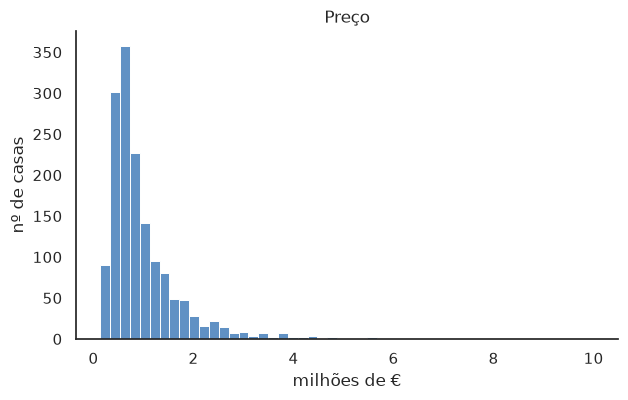

In [9]:
# Distribuição do preço, em milhões de euros
plt.figure(figsize=(7, 4))
sns.histplot(df["preco"] / 1_000_000, bins=50, color=COR)
plt.title("Preço")
plt.xlabel("milhões de €")
plt.ylabel("nº de casas")
plt.show()

Metade das casas custa entre 0,5 e 1,2 M€, mas algumas chegam aos 10 M€: a distribuição tem uma cauda longa à direita.

As casas da cauda (as de luxo) são poucas e muito diferentes entre si. São tratadas como outliers na fase 8.

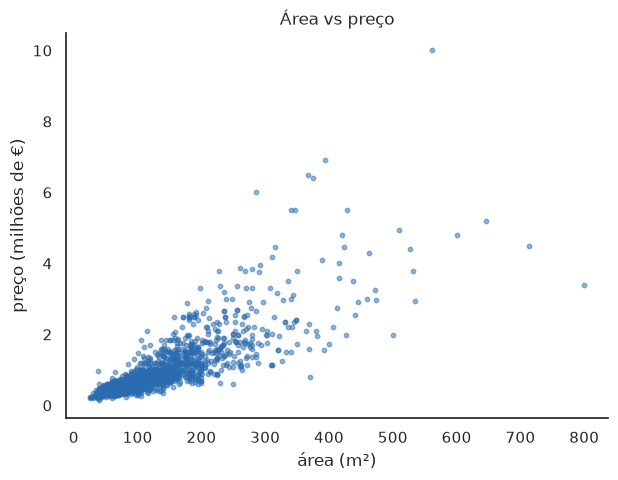

In [10]:
# Cada ponto é uma casa: área no eixo x, preço no eixo y (em milhões de €, para os números se lerem bem)
plt.figure(figsize=(7, 5))
plt.scatter(df["area_m2"], df["preco"] / 1_000_000, s=10, alpha=0.5, color=COR)   # alpha = transparência, mostra onde há mais pontos
plt.title("Área vs preço")
plt.xlabel("área (m²)")
plt.ylabel("preço (milhões de €)")
plt.show()

A área é o que mais explica o preço: os pontos sobem quase em linha reta. Mesmo assim, casas com a mesma área podem custar o dobro umas das outras, sobretudo por causa da localização, e a diferença aumenta nas casas maiores.

€/m² mediano em Lisboa: 6,801


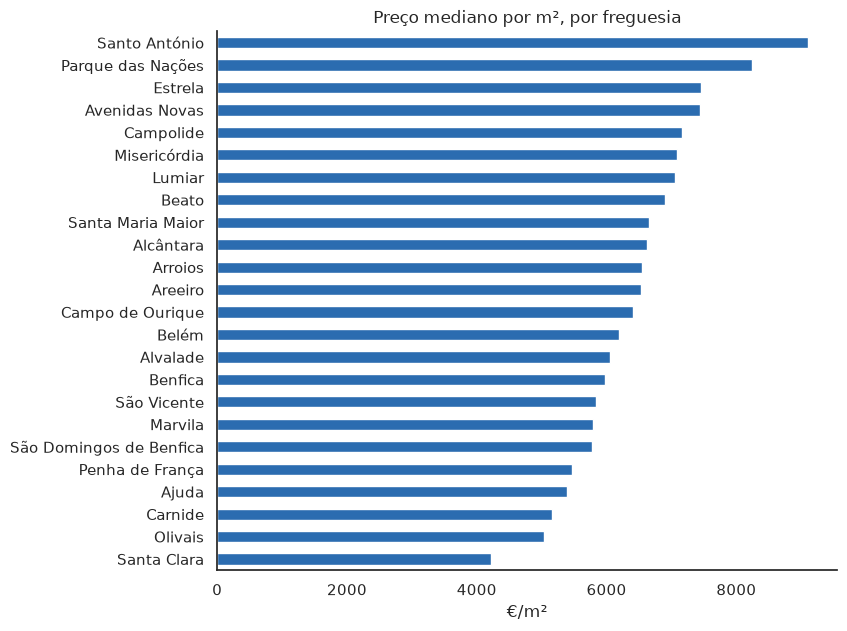

In [11]:
# Preço por m² de cada casa e, depois, a mediana por freguesia
# (a mediana é o valor do meio: não é puxada pelas poucas casas muito caras, ao contrário da média)
preco_m2 = df["preco"] / df["area_m2"]
m2_freguesia = preco_m2.groupby(df["freguesia"]).median().sort_values()
print(f"€/m² mediano em Lisboa: {preco_m2.median():,.0f}")

plt.figure(figsize=(8, 7))
m2_freguesia.plot.barh(color=COR)
plt.title("Preço mediano por m², por freguesia")
plt.xlabel("€/m²")
plt.ylabel("")
plt.show()

A localização pesa muito. Em Santo António e no Parque das Nações o m² passa os 8 000 €; em Santa Clara fica perto dos 4 000 €.

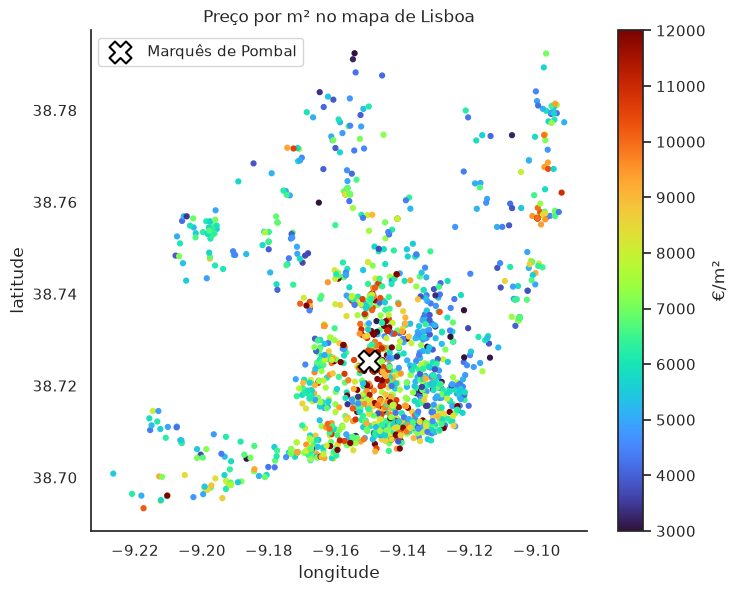

In [12]:
# Mapa: cada ponto é uma casa, colorida pelo preço por m² (azul = mais barato, vermelho = mais caro).
# As cores vão de 3 000 a 12 000 €/m²; as poucas casas fora deste intervalo ficam com a cor do extremo.
plt.figure(figsize=(8, 6.5))
pontos = plt.scatter(df["longitude"], df["latitude"], c=preco_m2, cmap="turbo", vmin=3000, vmax=12000, s=12)
plt.colorbar(pontos, label="€/m²")
plt.scatter(-9.1500, 38.7253, marker="X", s=250, color="white", edgecolor="black", linewidth=1.5, label="Marquês de Pombal")  # referência do centro
plt.legend()
plt.title("Preço por m² no mapa de Lisboa")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.show()

As casas mais caras por m² concentram-se no centro (Santo António, Avenidas Novas, Estrela) e no Parque das Nações, a nordeste. A norte (Carnide, Santa Clara) os preços descem. Não é só a distância ao centro que conta: há zonas caras longe do Marquês de Pombal.

longitude     -0.11
latitude       0.01
andar          0.24
quartos        0.58
casas_banho    0.77
area_m2        0.86
dtype: float64


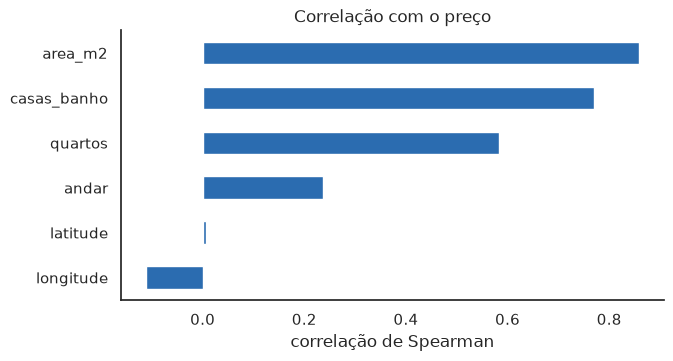

In [13]:
# Correlação de cada variável numérica com o preço (correlação de Spearman).
# A de Spearman compara a ordem dos valores (a casa maior, a 2.ª maior...), por isso a cauda longa do preço não a distorce.
# Vai de -1 a 1: perto de 1 = quando uma sobe, a outra também sobe; perto de 0 = não há relação.
numericas = ["area_m2", "quartos", "casas_banho", "andar", "latitude", "longitude"]
correlacao = df[numericas].corrwith(df["preco"], method="spearman").sort_values()
print(correlacao.round(2))

plt.figure(figsize=(7, 3.5))
correlacao.plot.barh(color=COR)
plt.title("Correlação com o preço")
plt.xlabel("correlação de Spearman")
plt.show()

A área (0,86), as casas de banho (0,77) e os quartos (0,58) acompanham o preço. A latitude e a longitude quase não têm correlação, mas isso não quer dizer que a localização não conte: o preço não sobe simplesmente "para norte" ou "para leste", varia por zonas, como se viu no mapa. É por isso que a freguesia também entra no modelo.

## 6. Novas variáveis (feature engineering)

Uma variável nova, criada a partir das coordenadas:

- `dist_centro_km`: distância em km à Praça do Marquês de Pombal.

Não crio variáveis como a área por divisão (área ÷ quartos): seria a mesma informação que a área e o número de quartos já dão ao modelo.

In [14]:
# Ponto de referência do centro de Lisboa: Praça do Marquês de Pombal
CENTRO_LAT = 38.7253
CENTRO_LON = -9.1500

def criar_variaveis(dados):
    """Acrescenta a variável nova. É uma função porque volta a ser usada na fase 16, para uma casa nova."""
    dados = dados.copy()   # trabalhar numa cópia, para não mexer na tabela original

    # Distância ao centro em km: 1 grau de latitude ≈ 111 km e, em Lisboa, 1 grau de longitude ≈ 87 km.
    # É uma conta "plana", que chega para distâncias dentro de uma cidade (entre cidades usa-se a fórmula de haversine).
    km_norte_sul = (dados["latitude"] - CENTRO_LAT) * 111
    km_este_oeste = (dados["longitude"] - CENTRO_LON) * 87
    dados["dist_centro_km"] = np.sqrt(km_norte_sul**2 + km_este_oeste**2)   # teorema de Pitágoras
    return dados

df = criar_variaveis(df)
df[["latitude", "longitude", "dist_centro_km", "preco"]].head()

,latitude,longitude,dist_centro_km,preco
0,38.74,-9.16,2.14,660000
1,38.72,-9.16,0.98,1495000
2,38.74,-9.16,1.98,555000
3,38.71,-9.13,2.14,1550000
4,38.77,-9.17,5.45,520000


## 7. Divisão em treino e teste

80% das casas servem para treinar o modelo e 20% ficam guardadas para o teste final. O teste faz de casas novas, que o modelo nunca viu.

In [15]:
# stratify: faz com que o treino e o teste tenham a mesma mistura de casas baratas e caras
# (pd.qcut parte o preço em 5 grupos do mesmo tamanho, do mais barato ao mais caro)
train, test = train_test_split(
    df,
    test_size=0.2,                                       # 20% para teste
    random_state=SEED,                                   # divisão sempre igual
    stratify=pd.qcut(df["preco"], 5, labels=False),
)

# .copy() cria tabelas independentes, que podem ser alteradas sem avisos do pandas
train = train.copy()
test = test.copy()
print("casas no treino:", len(train), "| casas no teste:", len(test))

casas no treino: 1223 | casas no teste: 306


## 8. Outliers

Há poucas casas muito caras (de luxo), que são a exceção e não a regra. O modelo aprende mal com elas e elas puxam o erro para cima, por isso ficam de fora.

Para decidir a partir de que preço uma casa é outlier uso a **regra do IQR**, a mais comum:

- **Q1** é o preço abaixo do qual estão 25% das casas; **Q3**, o preço abaixo do qual estão 75%.
- **IQR = Q3 − Q1** é a largura da "zona normal" de preços.
- É **outlier** uma casa acima de **Q3 + 1,5 × IQR**.

O limite é calculado **só com o treino**, porque é uma conta feita com os dados (como a mediana da fase 9), e depois é aplicado ao treino e ao teste. Assim, as métricas do teste valem para casas até este limite, que é o âmbito do modelo.

In [16]:
# Regra do IQR, calculada só com o TREINO
q1 = train["preco"].quantile(0.25)        # 25% das casas custam menos do que isto
q3 = train["preco"].quantile(0.75)        # 75% das casas custam menos do que isto
iqr = q3 - q1                             # largura da zona "normal" de preços
limite = q3 + 1.5 * iqr                   # acima disto, a casa é considerada outlier
print(f"Q1 = {q1:,.0f} €   Q3 = {q3:,.0f} €   IQR = {iqr:,.0f} €")
print(f"Limite: {limite:,.0f} €")

# Tirar as casas acima do limite, no treino e no teste (o limite é o mesmo, calculado no treino)
antes_treino = len(train)
antes_teste = len(test)
train = train[train["preco"] <= limite].copy()
test = test[test["preco"] <= limite].copy()
print("outliers removidos do treino:", antes_treino - len(train), "| ficam:", len(train))
print("outliers removidos do teste:", antes_teste - len(test), "| ficam:", len(test))

Q1 = 519,000 €   Q3 = 1,190,000 €   IQR = 671,000 €
Limite: 2,196,500 €
outliers removidos do treino: 85 | ficam: 1138
outliers removidos do teste: 22 | ficam: 284


## 9. Valores em falta

Regra base: os valores usados para preencher as falhas são calculados **só com o treino** e depois aplicados ao treino e ao teste. Se o teste entrasse nestas contas, o modelo estaria a "espreitar" as casas que deve ver pela primeira vez.

- **Números** (andar, casas de banho): a **mediana** do treino, que não é afetada por valores extremos.
- **Estado**: a categoria **"desconhecido"**. Não se inventa um valor, e "não indicado" pode ser informação útil para o modelo.

As colunas sim/não já não têm falhas: na fase 4, quando o anúncio não dizia nada, ficaram com 0 (não tem).

In [17]:
# Quantos valores faltam em cada coluna do treino (só as colunas que têm falhas)
falta = train.isna().sum()
falta[falta > 0]

casas_banho      2
andar          185
estado          18
dtype: int64

In [18]:
# Números: preencher com a mediana calculada no TREINO
for coluna in ["andar", "casas_banho"]:
    mediana = train[coluna].median()               # calculada só com o treino
    train[coluna] = train[coluna].fillna(mediana)
    test[coluna] = test[coluna].fillna(mediana)    # o teste usa a mesma mediana do treino
    print(coluna, "preenchido com a mediana:", mediana)

# Estado: preencher com "desconhecido"
train["estado"] = train["estado"].fillna("desconhecido")
test["estado"] = test["estado"].fillna("desconhecido")

# Confirmar que já não falta nenhum valor (se faltar, o assert interrompe o notebook com um erro)
assert train.isna().sum().sum() == 0
assert test.isna().sum().sum() == 0

andar preenchido com a mediana: 2.0
casas_banho preenchido com a mediana: 2.0


## 10. Codificação e normalização

Em muitos projetos, nesta fase faz-se **one-hot encoding** (transformar categorias, como a freguesia, em colunas de 0 e 1) e **normalização** (pôr os números todos na mesma escala). Aqui não é preciso fazê-lo à mão, porque o AutoGluon trata disso por dentro, à medida de cada modelo:

- Os modelos de árvores (LightGBM, CatBoost, XGBoost, Random Forest, Extra Trees) decidem por cortes, do tipo "área > 100 m²?". A escala dos números não muda nada, por isso não precisam de normalização, e o AutoGluon converte as categorias da forma que cada um precisa.
- Para as redes neuronais, o AutoGluon normaliza os números e converte as categorias automaticamente.

Fazê-lo à mão seria repetir trabalho: só a freguesia, com 24 valores diferentes, daria 24 colunas novas de 0 e 1.

## 11. Modelo de referência (baseline)

A regra simples da fase 1: preço por m² mediano da freguesia (calculado no treino) × área da casa.

In [19]:
# Preço por m² mediano de cada freguesia, calculado só com o treino
m2_treino = (train["preco"] / train["area_m2"]).groupby(train["freguesia"]).median()

# Previsão da baseline para as casas de teste: €/m² da freguesia × área
y_real = test["preco"]                                       # preço real das casas de teste, em €
y_baseline = test["freguesia"].map(m2_treino) * test["area_m2"]   # .map vai buscar o €/m² da freguesia de cada casa
assert y_baseline.notna().all()                              # todas as freguesias do teste existem no treino

def avaliar(real, previsto):
    """Calcula as métricas definidas na fase 1, a partir dos preços reais e dos previstos."""
    return {
        "MAE (€)": mean_absolute_error(real, previsto),                    # erro médio em euros
        "MAPE (%)": 100 * mean_absolute_percentage_error(real, previsto),  # erro médio em percentagem
        "Erro mediano (%)": 100 * np.median(np.abs(previsto - real) / real),  # metade das casas erra menos do que isto
        "RMSE (€)": root_mean_squared_error(real, previsto),               # como o MAE, mas os erros grandes pesam mais
        "R²": r2_score(real, previsto),                                    # 1 = perfeito
    }

pd.DataFrame({"baseline": avaliar(y_real, y_baseline)}).T

,MAE (€),MAPE (%),Erro mediano (%),RMSE (€),R²
baseline,"190,160.15",23.05,18.60,"269,755.99",0.59


## 12. Treino com AutoGluon

Escolhi seis tipos de modelo para comparar: LightGBM, CatBoost, XGBoost, Random Forest, Extra Trees e uma rede neuronal. O AutoGluon treina-os todos, compara-os com validação cruzada e junta os melhores num só modelo (*ensemble*).

In [20]:
# Começar com a pasta dos modelos vazia, para não misturar modelos de execuções diferentes
shutil.rmtree("AutogluonModels/lisboa", ignore_errors=True)

predictor = TabularPredictor(
    label="preco",                           # a coluna a prever (em €)
    eval_metric="mean_absolute_error",       # o erro que o AutoGluon tenta reduzir (MAE, o erro médio em euros)
    path="AutogluonModels/lisboa",           # pasta onde os modelos ficam guardados
).fit(
    train,                                   # treina só com o treino; o teste fica de fora
    presets="good_quality",                  # configuração pronta: bom equilíbrio entre qualidade e tempo
    num_stack_levels=0,                      # só uma camada de modelos, com o ensemble por cima: mais simples e mais rápido de treinar
    hyperparameters={                        # os tipos de modelo a comparar, cada um com a configuração por defeito
        "GBM": {},                           # LightGBM
        "CAT": {},                           # CatBoost
        "XGB": {},                           # XGBoost
        "RF": {},                            # Random Forest
        "XT": {},                            # Extra Trees
        "NN_TORCH": {},                      # rede neuronal
    },
    save_bag_folds=True,                     # a configuração good_quality apaga os modelos de cada fold; ficam guardados para avaliar também as versões _BAG_L1
    verbosity=0,                             # sem mensagens durante o treino: o resultado vê-se na tabela a seguir
)

Os nomes dos modelos seguem uma regra:

- **`_BAG_L1`**: o modelo foi treinado 8 vezes com validação cruzada (*bagging*); a previsão é a média das 8 versões.
- **`WeightedEnsemble_L2`**: média pesada dos melhores modelos. Chama-se L2 porque fica "por cima" dos outros, numa 2.ª camada.
- **`_FULL`**: o mesmo modelo, treinado de novo com todo o treino de uma só vez. Fica mais leve e mais rápido a prever.

Para cada um calculo as mesmas métricas da baseline, nas casas de teste.

In [21]:
# Para cada modelo treinado: prever as casas de teste e calcular as métricas
por_modelo = {}
for nome in predictor.model_names():
    previsto = predictor.predict(test, model=nome)           # previsão deste modelo, em euros
    por_modelo[nome] = avaliar(y_real, previsto)

tabela = pd.DataFrame(por_modelo).T                          # uma linha por modelo, uma coluna por métrica

# Segundos de treino de cada modelo, tirados do ranking do AutoGluon (nos ensembles, só o passo de juntar os outros)
tabela["treino (s)"] = predictor.leaderboard().set_index("model")["fit_time_marginal"]

print("Modelo que o AutoGluon usa por defeito:", predictor.model_best)
tabela.sort_values("MAE (€)")                                # do menor erro para o maior

Modelo que o AutoGluon usa por defeito: WeightedEnsemble_L2_FULL


,MAE (€),MAPE (%),Erro mediano (%),RMSE (€),R²,treino (s)
WeightedEnsemble_L2_FULL,"121,041.24",14.68,10.57,"181,029.84",0.82,0.03
CatBoost_BAG_L1_FULL,"122,674.45",14.57,11.73,"180,259.77",0.82,1.55
WeightedEnsemble_L2,"123,265.75",14.73,10.20,"183,828.59",0.81,0.03
CatBoost_BAG_L1,"125,291.86",14.88,11.15,"183,776.31",0.81,19.43
NeuralNetTorch_BAG_L1,"126,792.77",15.23,11.18,"188,483.72",0.80,50.77
NeuralNetTorch_BAG_L1_FULL,"129,214.24",16.00,12.10,"192,608.89",0.79,4.98
XGBoost_BAG_L1_FULL,"130,788.52",16.02,12.07,"198,296.19",0.78,0.31
XGBoost_BAG_L1,"132,305.16",15.93,12.31,"197,446.97",0.78,14.11
LightGBM_BAG_L1,"133,250.39",16.15,12.53,"196,490.72",0.78,10.82
LightGBM_BAG_L1_FULL,"135,968.34",16.49,12.32,"199,788.25",0.78,0.39


O AutoGluon usa por defeito o `WeightedEnsemble_L2_FULL`, uma média pesada dos melhores modelos. A escolha é feita pela **validação**, durante o treino, sem olhar para o teste: escolher pelo teste seria fazer batota, porque o teste deixaria de ser uma surpresa para o modelo. Aqui, o modelo escolhido é também o que tem o menor MAE no teste (121 mil €).

Sozinhos, os melhores são o CatBoost (entre 123 e 125 mil €) e a rede neuronal (entre 127 e 129 mil €), que são também os que mais tempo demoram a treinar. O XGBoost e o LightGBM ficam entre 131 e 136 mil €, e o Extra Trees e o Random Forest são os mais fracos (137 e 139 mil €).

No Random Forest e no Extra Trees, a versão `_FULL` é igual à original, porque estes modelos já usam todos os dados no treino.

## 13. Avaliação no teste

In [22]:
# Prever o preço das casas de teste (em euros)
y_previsto = predictor.predict(test)

# Comparar o AutoGluon com a baseline, nas mesmas casas
pd.DataFrame({"baseline": avaliar(y_real, y_baseline), "AutoGluon": avaliar(y_real, y_previsto)}).T

,MAE (€),MAPE (%),Erro mediano (%),RMSE (€),R²
baseline,"190,160.15",23.05,18.60,"269,755.99",0.59
AutoGluon,"121,041.24",14.68,10.57,"181,029.84",0.82


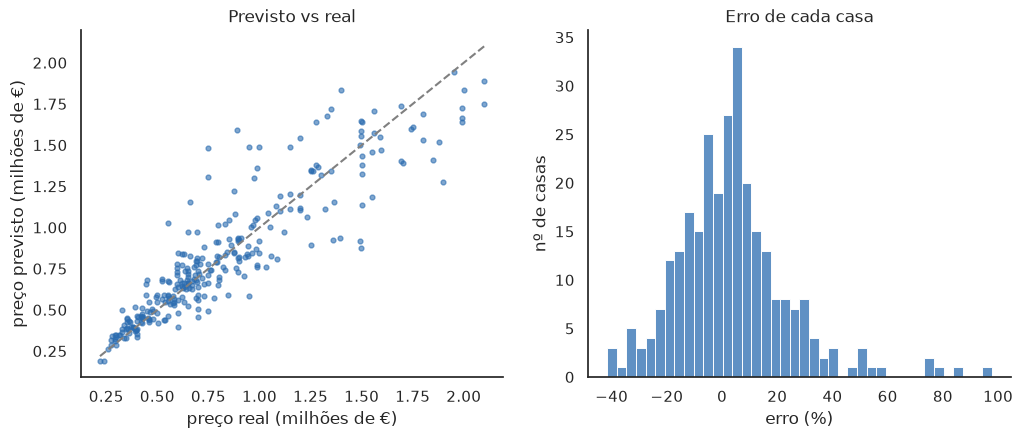

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Esquerda: preço previsto vs real, em milhões de €. Uma previsão perfeita ficava em cima da linha tracejada.
real_m = y_real / 1_000_000
previsto_m = y_previsto / 1_000_000
ax[0].scatter(real_m, previsto_m, s=12, alpha=0.6, color=COR)
ax[0].plot([real_m.min(), real_m.max()], [real_m.min(), real_m.max()], "--", color="gray")
ax[0].set(title="Previsto vs real", xlabel="preço real (milhões de €)", ylabel="preço previsto (milhões de €)")

# Direita: erro de cada casa em percentagem (positivo = o modelo previu acima do preço real)
erro_pct = (y_previsto - y_real) / y_real * 100
sns.histplot(erro_pct, bins=40, color=COR, ax=ax[1])
ax[1].set(title="Erro de cada casa", xlabel="erro (%)", ylabel="nº de casas")
plt.show()

O AutoGluon bate a baseline em todas as métricas: o erro médio desce de 190 mil € para 121 mil € (−36%), o erro percentual de 23% para 15% e o R² sobe de 0,59 para 0,82. O erro mediano desce de 19% para 11%: metade das casas fica com um erro abaixo de 11%.

No gráfico, os pontos seguem a linha tracejada. Perto dos 2 M€ o modelo ainda tende a prever um pouco abaixo do real.

## 14. Análise de erros

Em que casas é que o modelo falha mais?

In [24]:
# Erro (em %, sem sinal) de cada casa de teste, ao lado das suas características
erros = test.copy()
erros["preco_real"] = y_real
erros["preco_previsto"] = y_previsto
erros["erro_pct"] = erro_pct.abs()

# Erro mediano por freguesia (só freguesias com pelo menos 5 casas no teste, para não tirar conclusões de 1 ou 2 casas)
por_freguesia = erros.groupby("freguesia")["erro_pct"].agg(["median", "count"])
por_freguesia[por_freguesia["count"] >= 5].sort_values("median").round(1)

,median,count
freguesia,,
Lumiar,2.80,11
Parque das Nações,5.00,9
Beato,5.30,6
Estrela,6.20,28
Campolide,6.90,14
Alcântara,7.30,5
Marvila,7.40,6
Benfica,7.50,8
Areeiro,7.80,8


In [25]:
# As 5 casas onde o modelo mais falhou (em %)
mostrar = ["freguesia", "tipo", "area_m2", "quartos", "estado", "preco_real", "preco_previsto", "erro_pct"]
erros.sort_values("erro_pct", ascending=False)[mostrar].head(5)

,freguesia,tipo,area_m2,quartos,estado,preco_real,preco_previsto,erro_pct
851,Arroios,apartamento,155,4,bom,749000,"1,480,166.75",97.62
554,Santo António,apartamento,119,3,bom,550000,"1,025,999.31",86.55
760,Santa Maria Maior,duplex,225,4,bom,890000,"1,591,357.88",78.80
0,Avenidas Novas,apartamento,151,2,novo,660000,"1,155,462.50",75.07
1188,Misericórdia,apartamento,192,2,bom,750000,"1,305,717.38",74.10


O modelo acerta melhor em zonas mais recentes e uniformes, como o Lumiar (3%) e o Parque das Nações (5%), e falha mais em zonas antigas, como Santa Maria Maior (17%) e Campo de Ourique (16%). Aí, casas com a mesma área variam muito com o estado do prédio, a vista ou as obras feitas, e nada disso está nos dados.

As piores previsões são casas grandes anunciadas muito abaixo do preço da zona, por exemplo 155 m² por 749 mil € em Arroios (cerca de 4 800 €/m²), que o modelo estima em quase 1,5 M€. O modelo prevê o valor normal da zona; é provável que estas casas precisem de obras, apesar de quase todas estarem marcadas como "bom", ou que a área esteja mal escrita no anúncio.

## 15. Importância das variáveis

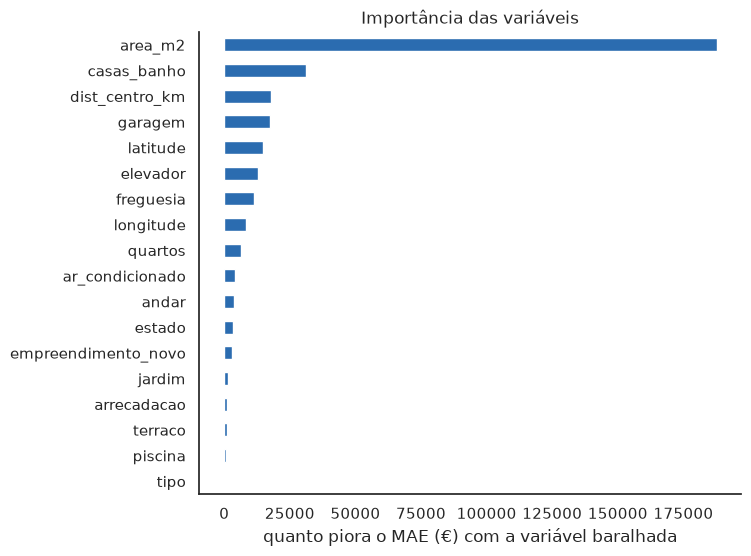

In [26]:
# O AutoGluon baralha os valores de uma coluna de cada vez e mede quanto piora o erro.
# Quanto mais o erro piora, mais o modelo depende dessa variável.
importancia = predictor.feature_importance(test, silent=True)["importance"]

plt.figure(figsize=(7, 6))
importancia.sort_values().plot.barh(color=COR)
plt.title("Importância das variáveis")
plt.xlabel("quanto piora o MAE (€) com a variável baralhada")
plt.show()

A área é de longe a variável mais importante: baralhá-la faz o erro médio subir mais de 150 mil €. Seguem-se as casas de banho, a distância ao centro e a garagem. A localização aparece repartida por várias variáveis (distância ao centro, latitude, freguesia, longitude) e, somadas, pesam bastante. O elevador também ajuda.

O tipo de casa, a piscina, o terraço, a arrecadação e o jardim quase não contam: a informação que trazem já está na área e na localização.

## 16. Previsão para uma casa nova

O modelo fica guardado em disco. Aqui é carregado de novo, como se fosse usado noutro programa, para estimar o preço de uma casa inventada.

In [27]:
# Carregar o modelo guardado na fase 12
modelo = TabularPredictor.load("AutogluonModels/lisboa")

# Uma casa inventada: T2 com 95 m² num 3.º andar, perto do Saldanha
nova_casa = pd.DataFrame([{
    "area_m2": 95, "quartos": 2, "casas_banho": 2, "andar": 3,
    "latitude": 38.7369, "longitude": -9.1427,
    "freguesia": "Avenidas Novas",
    "tipo": "apartamento", "estado": "bom", "empreendimento_novo": 0,
    "elevador": 1, "garagem": 0, "ar_condicionado": 1,                # 1 = tem, 0 = não tem
    "arrecadacao": 0, "jardim": 0, "piscina": 0, "terraco": 0,
}])

nova_casa = criar_variaveis(nova_casa)              # a mesma variável nova da fase 6 (distância ao centro)
preco = modelo.predict(nova_casa).iloc[0]           # prever o preço, em euros
print(f"Preço estimado: {preco:,.0f} €")

Preço estimado: 745,192 €


## 17. Conclusões e limitações

Para apartamentos até cerca de 2,2 M€, o modelo estima o preço pedido com um erro médio de cerca de 121 mil € (15%), contra 190 mil € (23%) da regra simples do €/m² por freguesia. Para o T2 de exemplo nas Avenidas Novas, a estimativa é de cerca de 745 mil €.

Limitações:

- O modelo **não serve para casas de luxo** (acima de cerca de 2,2 M€): nunca viu casas assim e iria subestimá-las.
- São **preços pedidos** nos anúncios, não preços de venda. As casas costumam vender abaixo do valor anunciado.
- É uma única recolha, com cerca de 1 400 casas. O mercado muda, e o modelo precisa de dados novos para continuar útil.
- Faltam informações que os anúncios não dão de forma organizada: estado real do prédio, vista, exposição solar, ano de construção.